# RollBack SMC gaussiano su GPU: due correzioni, una popolazione

Runtime Colab: **GPU**. `Run all` installa eventuali dipendenze mancanti, esegue i test, il pilot e gli esperimenti, salva tabelle e grafici nella cartella relativa `rollback_gpu_results/`. Nessun modello linguistico e nessun file locale esterno.

Una particella è la traiettoria completa $\tau=(x_T,\ldots,x_0)$, con $x_T=0$, $T=16$ e $Q_t(x_{t-1}\mid x_t)=\mathcal N(x_t,1/T)$. La legge originale è $P$, quindi $x_0\sim\mathcal N(0,1)$. Usiamo $\Phi(\tau)=x_0$ e $A=\{x_0\ge a\}$, dove $a=\Phi_{\rm normale}^{-1}(0.999)$ è calcolato dalla normale teorica: $p_A=P(A)=0.001$ esatto.

Il pilot usa $N=64$; l'esperimento principale usa $N=128$. Per ognuno dei **quattro tilt terminali separati** $\lambda\in\{0.5,1,1.5,2\}$, la schedule interna è $R=4$, $\beta_k=k\lambda/4$. $\pi_k(\tau)\propto P(\tau)e^{\beta_k\Phi(\tau)}$ e $G_k(\tau)=e^{(\beta_k-\beta_{k-1})\Phi(\tau)}$. Il kernel $M_k$ sceglie $d$ uniformemente in $\{1,\ldots,16\}$, conserva il prefisso, rigenera il suffisso secondo $P$ e accetta con probabilità $1\wedge e^{\beta_k[\Phi(\tau')-\Phi(\tau)]}$. Vi è **una** mutazione per livello.

Prima della mutazione, i pesi sono aggiornati con $G_k(\tau_{k-1}^{(n)})$. In entrambi i rami,
$$\widehat Z_k=\widehat Z_{k-1}\sum_n\overline W_{k-1}^{(n)}G_k(\tau_{k-1}^{(n)}),\qquad \widehat Z_0=1.$$
Dopo la normalizzazione dei pesi si applica resampling systematic solo se $\mathrm{ESS}/N<0.5$ e $k<R$; in tal caso i pesi diventano $1/N$, altrimenti restano quelli normalizzati. **Nessun resampling finale.** La mutazione $M_k$ segue in entrambi i casi.

Dalla **stessa popolazione** terminale si calcolano
$$\widehat p_{A,R}^{SMC}=\widehat Z_R\sum_n\overline W_R^{(n)}e^{-\lambda\Phi(\tau_R^{(n)})}\mathbf1_A(\tau_R^{(n)}),$$
$$\widehat p_{A,R}^{SNIS}=\frac{\sum_n\overline W_R^{(n)}e^{-\lambda\Phi(\tau_R^{(n)})}\mathbf1_A(\tau_R^{(n)})}{\sum_n\overline W_R^{(n)}e^{-\lambda\Phi(\tau_R^{(n)})}}.$$
Il confronto principale usa crude MC da **traiettorie complete sotto $P$** sullo stesso dispositivo. Il campionamento diretto di $x_0\sim\mathcal N(0,1)$ è mostrato separatamente perché disponibile solo grazie a questo toy model. Le barre d'errore provengono da repliche indipendenti dell'intero algoritmo; la CLT della versione senza resampling **non** è usata per queste run.

Per ogni livello registriamo $\mathrm{ESS}/N$ e $\max_n\overline W_k^{(n)}$ **dopo $G_k$ ma prima dell'eventuale resampling**, nonché la decisione di resampling. Alla fine registriamo queste due quantità per i pesi SMC $\overline W_R^{(n)}$. Per la correzione inversa normalizziamo **su tutte le particelle** $\overline W_R^{(n)}e^{-\lambda\Phi(\tau_R^{(n)})}$, senza $\mathbf1_A$, e ricalcoliamo $\mathrm{ESS}/N$ e peso massimo. La frazione di antenati iniziali distinti è aggiornata quando il resampling copia intere traiettorie. Le distribuzioni fra run sono mostrate con quantili e grafici, insieme alle associazioni descrittive con bias e RMSE.

In [1]:
import importlib.util, subprocess, sys
missing = [name for name in ['numpy', 'scipy', 'pandas', 'matplotlib', 'torch'] if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Dependencies available; CUDA runtime is required.')

Dependencies available; CUDA runtime is required.


In [2]:
"""GPU-only full-trajectory RollBack SMC estimators and two MC controls."""
from dataclasses import dataclass
import math
import time
import numpy as np
import torch
from scipy.stats import norm

P_A = 0.001
a = float(norm.isf(P_A))  # Theoretical quantile. NEVER estimated from samples.
T = 16
D = 16  # Fixed for every experiment.
DTYPE = torch.float32
DEVICE = torch.device("cuda:0")


@dataclass(frozen=True)
class GPUConfig:
    n: int
    levels: int
    tilt: float


def require_gpu():
    if not torch.cuda.is_available():
        raise RuntimeError("A CUDA GPU is required. In Colab select a GPU runtime; no CPU fallback is used.")
    torch.set_grad_enabled(False)
    return {"device": str(DEVICE), "gpu": torch.cuda.get_device_name(DEVICE),
            "torch": torch.__version__, "cuda_runtime": torch.version.cuda,
            "dtype": str(DTYPE), "T": T, "D": D, "threshold": a, "p_A": P_A}


def generator(seed):
    return torch.Generator(device=DEVICE).manual_seed(int(seed))


def gaussian_paths(n, rng):
    innovations = torch.randn((n, T), device=DEVICE, dtype=DTYPE, generator=rng) / math.sqrt(T)
    return torch.cat((torch.zeros((n, 1), device=DEVICE, dtype=DTYPE), innovations.cumsum(dim=1)), dim=1)


def rollback(paths, beta, rng):
    n = paths.shape[0]
    depths = torch.randint(1, D+1, (n,), device=DEVICE, generator=rng)
    cut = T-depths
    columns = torch.arange(T, device=DEVICE)[None, :]
    suffix = columns >= cut[:, None]
    # Padded GPU implementation: N*T normals are drawn, only sum(depths) used.
    noise = torch.randn((n, T), device=DEVICE, dtype=DTYPE, generator=rng) / math.sqrt(T)
    noise = torch.where(suffix, noise, 0.0)
    anchor = paths.gather(1, cut[:, None])
    future = anchor + noise.cumsum(dim=1)
    proposal = torch.cat((paths[:, :1], torch.where(suffix, future, paths[:, 1:])), dim=1)
    accept = torch.log(torch.rand(n, device=DEVICE, dtype=DTYPE, generator=rng)) < torch.minimum(
        torch.zeros((), device=DEVICE, dtype=DTYPE), beta*(proposal[:, -1]-paths[:, -1]))
    return torch.where(accept[:, None], proposal, paths), depths, accept


def systematic(log_weights, rng, offset=None):
    n = log_weights.numel()
    cumulative = log_weights.exp().cumsum(0)
    cumulative[-1] = 1.0
    if offset is None:
        offset = torch.rand((), device=DEVICE, generator=rng)
    points = (torch.arange(n, device=DEVICE, dtype=DTYPE) + offset)/n
    return torch.searchsorted(cumulative, points, right=False)


@torch.inference_mode()
def run_smc_population(config, seed, debug=False):
    rng = generator(seed)
    n = config.n
    paths = gaussian_paths(n, rng)
    log_w = torch.full((n,), -math.log(n), device=DEVICE, dtype=DTYPE)
    log_z = torch.zeros((), device=DEVICE, dtype=DTYPE)
    used_transitions = torch.tensor(n*T, device=DEVICE, dtype=torch.int64)
    roots = torch.arange(n, device=DEVICE)
    resampled = []
    ess_by_level = []
    max_weight_by_level = []
    history = []
    for k in range(1, config.levels+1):
        beta = config.tilt*k/config.levels
        increment = config.tilt/config.levels * paths[:, -1]
        if debug:
            old_x, old_w, old_z = paths[:, -1].clone(), log_w.clone(), log_z.clone()
        unnormalized = log_w + increment
        log_c = torch.logsumexp(unnormalized, 0)
        log_z = log_z + log_c  # Every level, including levels without resampling.
        log_w = unnormalized-log_c
        ess = torch.exp(-torch.logsumexp(2*log_w, 0))
        # Both diagnostics refer to the weighted population BEFORE selection.
        ess_by_level.append(ess/n)
        max_weight_by_level.append(log_w.max().exp())
        # The unavoidable ESS host decision and its synchronization are TIMED.
        selected = k < config.levels and bool((ess < 0.5*n).item())
        if selected:
            parents = systematic(log_w, rng)
            paths = paths.index_select(0, parents)
            roots = roots.index_select(0, parents)
            log_w = torch.full_like(log_w, -math.log(n))
            resampled.append(k)
        paths, depths, accepted = rollback(paths, beta, rng)
        used_transitions += depths.sum()
        if debug:
            history.append({"level": k, "old_x": old_x, "old_log_w": old_w,
                            "old_log_z": old_z, "log_c": log_c.clone(),
                            "log_z": log_z.clone(), "ess": ess.clone(),
                            "max_weight_before": max_weight_by_level[-1].clone(),
                            "resampled": selected, "depths": depths.clone(),
                            "accepted": accepted.clone()})
    corrected_log_weights = log_w-config.tilt*paths[:, -1]
    # Score is x_0; event uses the theoretical Gaussian quantile.
    event = paths[:, -1] >= a
    log_num = torch.logsumexp(torch.where(event, corrected_log_weights, -torch.inf), 0)
    log_den = torch.logsumexp(corrected_log_weights, 0)
    normalized_corrected_log_weights = corrected_log_weights-log_den
    terminal_ess_fraction = torch.exp(-torch.logsumexp(2*log_w, 0))/n
    reverse_ess_fraction = torch.exp(-torch.logsumexp(2*normalized_corrected_log_weights, 0))/n
    distinct_roots = torch.unique(roots).numel()
    # BOTH estimators use this SAME weighted terminal population and therefore
    # share the entire generation, weighting, resampling and mutation cost.
    estimate_smc = float(torch.exp(log_z+log_num).item())
    estimate_snis = float(torch.exp(log_num-log_den).item())
    result = {"smc": estimate_smc, "snis": estimate_snis,
              "z_hat": float(log_z.exp().item()),
              "reverse_mass": float(torch.exp(log_z+log_den).item()),
              "used_transitions": int(used_transitions.item()),
              "gaussian_variates_drawn": n*T*(config.levels+1),
              "resampling_count": len(resampled), "resampled_levels": resampled,
              "ess_by_level": torch.stack(ess_by_level).cpu().tolist(),
              "max_weight_by_level": torch.stack(max_weight_by_level).cpu().tolist(),
              "terminal_ess_fraction": float(terminal_ess_fraction.item()),
              "terminal_max_weight": float(log_w.max().exp().item()),
              "reverse_ess_fraction": float(reverse_ess_fraction.item()),
              "reverse_max_weight": float(normalized_corrected_log_weights.max().exp().item()),
              "distinct_roots": int(distinct_roots),
              "distinct_root_fraction": float(distinct_roots/n),
              "n": n, "R": config.levels, "lambda": config.tilt}
    if debug:
        result.update(paths=paths, log_weights=log_w, log_z=log_z,
                      roots=roots, history=history)
    return result


@torch.inference_mode()
def crude_paths(count, seed, chunk_size=262144):
    """Primary MC: explicitly generate complete paths from the SAME Q_t."""
    rng = generator(seed)
    hits = torch.zeros((), device=DEVICE, dtype=torch.int64)
    for first in range(0, count, chunk_size):
        paths = gaussian_paths(min(chunk_size, count-first), rng)
        hits += (paths[:, -1] >= a).sum()
    estimate = float((hits.to(torch.float64)/count).item())
    return {"estimate": estimate, "used_transitions": count*T,
            "gaussian_variates_drawn": count*T, "n": count, "R": 0, "lambda": 0,
            "resampling_count": 0, "resampled_levels": []}


@torch.inference_mode()
def crude_direct(count, seed, chunk_size=4194304):
    """Separate toy-specific control: X ~ N(0,1), without trajectories."""
    rng = generator(seed)
    hits = torch.zeros((), device=DEVICE, dtype=torch.int64)
    for first in range(0, count, chunk_size):
        x = torch.randn(min(chunk_size, count-first), device=DEVICE, dtype=DTYPE, generator=rng)
        hits += (x >= a).sum()
    estimate = float((hits.to(torch.float64)/count).item())
    return {"estimate": estimate, "used_transitions": 0,
            "gaussian_variates_drawn": count, "n": count, "R": 0, "lambda": 0,
            "resampling_count": 0, "resampled_levels": []}


def measured(function, *args):
    """Wall clock includes allocation, RNG setup, kernels, host ESS, correction.

    Warmup is separate. Synchronization before t0 drains prior work; final
    synchronization is inside the interval. No CUDA-event-only timing.
    """
    torch.cuda.synchronize(DEVICE)
    start = time.perf_counter()
    result = function(*args)
    torch.cuda.synchronize(DEVICE)
    elapsed = time.perf_counter()-start
    return result, elapsed


def make_seed(stream, config_id, rep, root=20260929):
    return int(np.random.SeedSequence([root, stream, config_id, rep]).generate_state(1, dtype=np.uint64)[0] % np.uint64(2**63-1))


def warmup(repetitions=30):
    start = time.perf_counter()
    for rep in range(repetitions):
        seed = make_seed(90, 0, rep)
        run_smc_population(GPUConfig(128, 4, 2), seed)
        crude_paths(32768, seed)
        crude_direct(1048576, seed)
    torch.cuda.synchronize(DEVICE)
    return time.perf_counter()-start


In [3]:
"""Reproducible GPU benchmark. Embedded without local imports in Colab notebook."""
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import norm

OUT = Path("rollback_gpu_results")
ROOT_SEED = 20260929
N = 128
PILOT_N = 64
R = 4
TILTS = [0.5, 1.0, 1.5, 2.0]
PILOT_REPS = 200
REPS = 1200
DIRECT_REPS = 600


def check_algorithm():
    """Check distribution, invariant kernel, exact branches, normalizer and estimates."""
    device = require_gpu()
    assert T == D == 16 and abs(a - norm.isf(P_A)) < 1e-14
    paths = gaussian_paths(131072, generator(make_seed(1, 0, 0)))
    mean, second = paths[:, -1].mean().item(), paths[:, -1].var(unbiased=True).item()
    assert abs(mean) < .012 and abs(second-1) < .018, (mean, second)
    assert torch.all(paths[:, 0] == 0)
    assert abs((paths[:, 1:]-paths[:, :-1]).var().item()-1/T) < .001

    n = 131072
    origin = gaussian_paths(n, generator(make_seed(1, 1, 0)))
    beta = 1.5
    # Exact tilted reference is used ONLY in this diagnostic, never as sampler.
    tilted = origin + torch.arange(T+1, device=DEVICE, dtype=DTYPE)[None, :] * (beta/T)
    moved, depths, accepted = rollback(tilted, beta, generator(make_seed(1, 2, 0)))
    counts = torch.bincount(depths, minlength=D+1)[1:].cpu().numpy()
    expected = n/D
    assert counts.shape == (16,) and np.max(abs(counts-expected))/expected < .055
    cut = T-depths
    cols = torch.arange(T+1, device=DEVICE)[None, :]
    assert torch.all(torch.where(cols <= cut[:, None], moved == tilted, True))
    tilt_mean = moved[:, -1].mean().item()
    tilt_var = moved[:, -1].var(unbiased=True).item()
    assert abs(tilt_mean-beta) < .025 and abs(tilt_var-1) < .025

    # Same deterministic systematic selection as NumPy/CPU reference.
    weights = np.array([.05, .35, .10, .50], dtype=np.float32)
    log_weights = torch.tensor(np.log(weights), device=DEVICE)
    offset = torch.tensor(.37, device=DEVICE)
    gpu_parent = systematic(log_weights, generator(23), offset).cpu().numpy()
    cpu_parent = np.searchsorted(np.cumsum(weights), (np.arange(4)+.37)/4, side="left")
    np.testing.assert_array_equal(gpu_parent, cpu_parent)

    branch = {}
    for label, config in (("none", GPUConfig(128, 4, 0.0)),
                          ("selected", GPUConfig(128, 2, 4.0)),
                          ("final", GPUConfig(128, 1, 4.0))):
        result = run_smc_population(config, make_seed(2, len(branch), 0), debug=True)
        trace = result["history"]
        assert len(trace) == config.levels
        for h in trace:
            log_c = torch.logsumexp(h["old_log_w"] + config.tilt/config.levels*h["old_x"], 0)
            assert abs((h["log_c"]-log_c).item()) < 2e-6
            assert abs((h["log_z"]-h["old_log_z"]-log_c).item()) < 2e-6
            assert h["resampled"] == (h["level"] < config.levels and h["ess"].item() < .5*config.n)
            pre_log_w = h["old_log_w"] + config.tilt/config.levels*h["old_x"]-log_c
            assert abs(result["ess_by_level"][h["level"]-1] - torch.exp(-torch.logsumexp(2*pre_log_w, 0)).item()/config.n) < 2e-6
            assert abs(result["max_weight_by_level"][h["level"]-1] - pre_log_w.max().exp().item()) < 2e-6
        assert not trace[-1]["resampled"]
        if label == "none":
            assert not result["resampled_levels"]
            assert abs(result["z_hat"]-1) < 1e-5
            assert result["distinct_root_fraction"] == 1.0
        if label == "selected":
            assert result["resampled_levels"]
            assert result["distinct_root_fraction"] < 1.0
        if label == "final":
            assert trace[-1]["ess"].item() < .5*config.n
        terminal = result["paths"][:, -1]
        weights_terminal = result["log_weights"].exp()
        assert abs(weights_terminal.sum().item()-1) < 2e-6
        corrected = weights_terminal*torch.exp(-config.tilt*terminal)
        numerator = (corrected*(terminal >= a)).sum().item()
        denominator = corrected.sum().item()
        assert abs(result["smc"]-result["z_hat"]*numerator) < 1e-5
        assert abs(result["snis"]-numerator/denominator) < 1e-6
        reverse_weights = corrected/denominator
        assert abs(result["terminal_ess_fraction"] - 1/(config.n*weights_terminal.square().sum().item())) < 2e-6
        assert abs(result["terminal_max_weight"] - weights_terminal.max().item()) < 2e-6
        assert abs(result["reverse_ess_fraction"] - 1/(config.n*reverse_weights.square().sum().item())) < 2e-6
        assert abs(result["reverse_max_weight"] - reverse_weights.max().item()) < 2e-6
        assert result["distinct_roots"] == torch.unique(result["roots"]).numel()
        branch[label] = {"ess": [float(h["ess"].item()) for h in trace],
                         "resampled_levels": result["resampled_levels"],
                         "z_hat": result["z_hat"],
                         "used_transitions": result["used_transitions"]}
    device.update({"x0_mean_test": mean, "x0_var_test": second,
                   "tilted_kernel_mean_test": tilt_mean, "tilted_kernel_var_test": tilt_var,
                   "depth_min_count": int(counts.min()), "depth_max_count": int(counts.max()),
                   "branch_tests": branch})
    return device


def records_for(method, count, reps, stream, config_id=0, tilt=0.0):
    records = []
    for rep in range(reps):
        seed = make_seed(stream, config_id, rep, ROOT_SEED)
        if method == "smc":
            value, seconds = measured(run_smc_population, GPUConfig(count, R, tilt), seed)
            common = {"lambda": tilt, "n": count, "R": R, "run": rep, "seed": seed,
                      "seconds": seconds, "z_hat": value["z_hat"],
                      "reverse_mass": value["reverse_mass"],
                      "resampling_count": value["resampling_count"],
                      "resampled_levels": ",".join(map(str, value["resampled_levels"])),
                      "ess_by_level": ",".join(f"{e:.6g}" for e in value["ess_by_level"]),
                      "max_weight_by_level": ",".join(f"{e:.6g}" for e in value["max_weight_by_level"]),
                      "terminal_ess_fraction": value["terminal_ess_fraction"],
                      "terminal_max_weight": value["terminal_max_weight"],
                      "reverse_ess_fraction": value["reverse_ess_fraction"],
                      "reverse_max_weight": value["reverse_max_weight"],
                      "distinct_root_fraction": value["distinct_root_fraction"],
                      "used_transitions": value["used_transitions"],
                      "gaussian_variates_drawn": value["gaussian_variates_drawn"]}
            for estimator in ("smc", "snis"):
                records.append({"method": estimator, "estimate": value[estimator], **common})
        else:
            fn = crude_paths if method == "crude_paths" else crude_direct
            value, seconds = measured(fn, count, seed)
            records.append({"method": method, "estimate": value["estimate"],
                            "lambda": tilt, "n": count, "R": 0, "run": rep, "seed": seed,
                            "seconds": seconds, "z_hat": np.nan, "reverse_mass": np.nan,
                            "resampling_count": 0, "resampled_levels": "",
                            "ess_by_level": "",
                            "max_weight_by_level": "",
                            "terminal_ess_fraction": np.nan,
                            "terminal_max_weight": np.nan,
                            "reverse_ess_fraction": np.nan,
                            "reverse_max_weight": np.nan,
                            "distinct_root_fraction": np.nan,
                            "used_transitions": value["used_transitions"],
                            "gaussian_variates_drawn": value["gaussian_variates_drawn"]})
    return records


def median_latency(fn, count, stream, config_id, reps=64):
    times = []
    for rep in range(reps):
        _, dt = measured(fn, count, make_seed(stream, config_id, rep, ROOT_SEED))
        times.append(dt)
    return float(np.median(times))


def match_count(target_seconds, fn, stream, config_id, initial, max_count):
    count = initial
    for iteration in range(7):
        duration = median_latency(fn, count, stream+iteration, config_id)
        ratio = np.clip(target_seconds/max(duration, 1e-9), .3, 3.0)
        updated = int(np.clip(round(count*ratio/256)*256, 256, max_count))
        if abs(updated-count) <= 256:
            break
        count = updated
    return count, median_latency(fn, count, stream+20, config_id, reps=96)


def summarize(frame):
    rows = []
    keys = ["method", "lambda", "n", "R"]
    for key, group in frame.groupby(keys, sort=True):
        vals = group.estimate.to_numpy(dtype=float)
        errs = vals-P_A
        sq = errs*errs
        b = len(vals)
        rmse = float(np.sqrt(sq.mean()))
        bias = float(errs.mean())
        variance = float(vals.var(ddof=1))
        # Independent whole-run uncertainty, not a no-resampling CLT.
        se_rmse = float(sq.std(ddof=1)/(2*np.sqrt(b)*rmse)) if rmse > 0 else np.nan
        rows.append(dict(zip(keys, key)) | {"reps": b, "bias": bias,
                    "bias_se": float(vals.std(ddof=1)/np.sqrt(b)),
                    "variance": variance, "rmse": rmse, "rmse_se": se_rmse,
                    "zero_fraction": float(np.mean(vals == 0)),
                    "median_ms": float(group.seconds.median()*1000),
                    "mean_ms": float(group.seconds.mean()*1000),
                    "median_transitions": float(group.used_transitions.median()),
                    "median_gaussian_draws": float(group.gaussian_variates_drawn.median()),
                    "resampling_run_fraction": float(np.mean(group.resampling_count > 0))})
    return pd.DataFrame(rows)


def plot_results(summary, out):
    smc = summary[summary.method.isin(["smc", "snis"])].sort_values("lambda")
    fixed = summary[(summary.method == "crude_paths") & (summary.n == N)]
    matched = summary[(summary.method == "crude_paths") & (summary.n != N)]
    direct = summary[summary.method == "crude_direct"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
    for method, label in (("smc", r"$\widehat p^{SMC}_{A,R}$"),
                          ("snis", r"$\widehat p^{SNIS}_{A,R}$")):
        f = smc[smc.method == method]
        axes[0].errorbar(f["lambda"], f.rmse, yerr=1.96*f.rmse_se, marker="o", capsize=2, label=label)
        axes[1].errorbar(f["lambda"], f.rmse, yerr=1.96*f.rmse_se, marker="o", capsize=2, label=label)
    if not fixed.empty:
        axes[0].axhline(fixed.iloc[0].rmse, color="black", linestyle="--", label=f"crude paths, N={N}")
    axes[1].errorbar(matched["lambda"], matched.rmse, yerr=1.96*matched.rmse_se,
                     marker="s", capsize=2, label="crude paths, matched GPU time")
    axes[1].errorbar(direct["lambda"], direct.rmse, yerr=1.96*direct.rmse_se,
                     marker="^", capsize=2, label="direct Gaussian, matched GPU time")
    axes[0].set_title("Same number of trajectories")
    axes[1].set_title("Same GPU wall-clock budget")
    for ax in axes:
        ax.set_xlabel(r"terminal tilt $\lambda=\beta_R$")
        ax.set_ylabel("RMSE vs exact $p_A=0.001$")
        ax.set_yscale("log")
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    fig.savefig(out / "rmse_comparison.png", dpi=180)
    plt.close(fig)


def diagnostic_tables(frame):
    """One record per level/run and empirical distributions across complete runs."""
    smc = frame[frame.method == "snis"].copy()
    records = []
    for row in smc.to_dict("records"):
        pre_ess = [float(x) for x in row["ess_by_level"].split(",")]
        pre_max = [float(x) for x in row["max_weight_by_level"].split(",")]
        resampled = {int(x) for x in str(row["resampled_levels"]).split(",") if x and x != "nan"}
        for k in range(1, R+1):
            records.append({"lambda": row["lambda"], "run": row["run"], "level": k,
                            "pre_ess_fraction": pre_ess[k-1],
                            "pre_max_weight": pre_max[k-1],
                            "resampled": int(k in resampled)})
    levels = pd.DataFrame(records)
    long = []
    for row in levels.to_dict("records"):
        for metric in ("pre_ess_fraction", "pre_max_weight", "resampled"):
            long.append({"lambda": row["lambda"], "run": row["run"],
                         "stage": f"before_resampling_k{row['level']}", "metric": metric,
                         "value": row[metric]})
    for row in smc.to_dict("records"):
        for metric, stage in (("terminal_ess_fraction", "terminal"),
                              ("terminal_max_weight", "terminal"),
                              ("reverse_ess_fraction", "reverse"),
                              ("reverse_max_weight", "reverse"),
                              ("distinct_root_fraction", "genealogy")):
            long.append({"lambda": row["lambda"], "run": row["run"],
                         "stage": stage, "metric": metric, "value": row[metric]})
    distribution = pd.DataFrame(long)
    quantiles = distribution.groupby(["lambda", "stage", "metric"]).value.agg(
        n="count", mean="mean", sd="std", minimum="min",
        p05=lambda x: x.quantile(.05), p25=lambda x: x.quantile(.25),
        median="median", p75=lambda x: x.quantile(.75),
        p95=lambda x: x.quantile(.95), maximum="max").reset_index()
    return levels, distribution, quantiles


def diagnostic_association(frame):
    """Descriptive conditional errors; not a causal or ESS guarantee analysis."""
    smc = frame[frame.method == "snis"].set_index(["lambda", "run"])
    rows = []
    for tilt in TILTS:
        group = smc.loc[tilt]
        for metric in ("terminal_ess_fraction", "reverse_ess_fraction",
                       "distinct_root_fraction"):
            values = group[metric]
            if values.nunique() <= 1:
                bins = pd.Series("all", index=values.index)
            else:
                bins = pd.qcut(values, 4, labels=False, duplicates="drop").astype(str)
            for bin_label in sorted(bins.unique()):
                selected = bins.index[bins == bin_label]
                for method in ("smc", "snis"):
                    method_runs = frame[(frame.method == method) & (frame["lambda"] == tilt)].set_index("run")
                    estimates = method_runs.loc[selected, "estimate"].to_numpy()
                    errors = estimates-P_A
                    rows.append({"lambda": tilt, "diagnostic": metric, "bin": bin_label,
                                 "method": method, "runs": len(estimates),
                                 "diagnostic_min": float(values.loc[selected].min()),
                                 "diagnostic_median": float(values.loc[selected].median()),
                                 "diagnostic_max": float(values.loc[selected].max()),
                                 "bias": float(errors.mean()),
                                 "rmse": float(np.sqrt(np.mean(errors*errors))),
                                 "zero_fraction": float(np.mean(estimates == 0))})
    return pd.DataFrame(rows)


def plot_diagnostics(levels, frame, out):
    smc = frame[frame.method == "snis"]
    colors = plt.cm.viridis(np.linspace(.12, .85, len(TILTS)))
    fig, axes = plt.subplots(3, 2, figsize=(12, 12), constrained_layout=True)
    for ax, metric, title in ((axes[0, 0], "pre_ess_fraction", "ESS/N before resampling"),
                              (axes[0, 1], "pre_max_weight", "Max normalized weight before resampling")):
        for tilt, color in zip(TILTS, colors):
            sub = levels[levels["lambda"] == tilt]
            q = sub.groupby("level")[metric].quantile([.05, .25, .5, .75, .95]).unstack()
            x = q.index.to_numpy(dtype=float)
            ax.fill_between(x, q[.05], q[.95], color=color, alpha=.12)
            ax.fill_between(x, q[.25], q[.75], color=color, alpha=.25)
            ax.plot(x, q[.5], marker="o", color=color, label=f"λ={tilt:g}")
        ax.set_title(title + "\n5–95%, 25–75%, median")
        ax.set_xlabel("SMC level k")
        ax.set_xticks(range(1, R+1))
        ax.grid(alpha=.2)
    axes[0, 0].axhline(.5, linestyle="--", color="black", linewidth=.8)
    axes[0, 0].legend(ncol=2, fontsize=8)
    for ax, pair, title in ((axes[1, 0], ("terminal_ess_fraction", "reverse_ess_fraction"), "Terminal vs corrected ESS/N"),
                            (axes[1, 1], ("terminal_max_weight", "reverse_max_weight"), "Terminal vs corrected max weight")):
        for index, (metric, color, offset, label) in enumerate(zip(pair, ("#3769a8", "#df7835"), (-.17, .17), ("SMC weights", "inverse-corrected"))):
            arrays = [smc[smc["lambda"] == tilt][metric].to_numpy() for tilt in TILTS]
            positions = np.arange(len(TILTS)) + offset
            bp = ax.boxplot(arrays, positions=positions, widths=.28, whis=[5,95], showfliers=False, patch_artist=True)
            for box in bp["boxes"]:
                box.set_facecolor(color)
                box.set_alpha(.6)
            ax.plot([], [], color=color, linewidth=7, alpha=.6, label=label)
        ax.set_xticks(range(len(TILTS)), [f"{t:g}" for t in TILTS])
        ax.set_xlabel("terminal tilt λ")
        ax.set_title(title + "\nbox: 25–75%; whiskers: 5–95%")
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    axes[2, 0].boxplot([smc[smc["lambda"] == tilt].distinct_root_fraction.to_numpy() for tilt in TILTS],
                       positions=np.arange(len(TILTS)), whis=[5,95], showfliers=False)
    axes[2, 0].set_xticks(range(len(TILTS)), [f"{t:g}" for t in TILTS])
    axes[2, 0].set_xlabel("terminal tilt λ")
    axes[2, 0].set_title("Distinct initial ancestor fraction (5–95% whiskers)")
    axes[2, 0].grid(alpha=.2)
    selection = levels.groupby(["lambda", "level"]).resampled.mean().unstack()
    for tilt, color in zip(TILTS, colors):
        axes[2, 1].plot(selection.columns, selection.loc[tilt], marker="o", color=color, label=f"λ={tilt:g}")
    axes[2, 1].set_xticks(range(1, R+1))
    axes[2, 1].set_xlabel("SMC level k")
    axes[2, 1].set_ylabel("fraction of runs with resampling")
    axes[2, 1].set_title("Systematic resampling activation")
    axes[2, 1].grid(alpha=.2)
    fig.savefig(out / "weight_degeneracy.png", dpi=170)
    plt.close(fig)


def plot_association(association, out):
    data = association[association.diagnostic == "reverse_ess_fraction"]
    colors = plt.cm.viridis(np.linspace(.12, .85, len(TILTS)))
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)
    for tilt, color in zip(TILTS, colors):
        for method, style in (("smc", "--"), ("snis", "-")):
            sub = data[(data["lambda"] == tilt) & (data.method == method)].sort_values("diagnostic_median")
            axes[0].plot(sub.diagnostic_median, sub.bias, marker="o", linestyle=style,
                         color=color, label=f"λ={tilt:g}, {method}")
            axes[1].plot(sub.diagnostic_median, sub.rmse, marker="o", linestyle=style, color=color)
            if method == "snis":
                axes[2].plot(sub.diagnostic_median, sub.zero_fraction, marker="o", color=color, label=f"λ={tilt:g}")
    for ax, title, ylabel in zip(axes, ("Conditional bias", "Conditional RMSE", "Zero-estimate fraction"),
                                  ("bias vs exact $p_A$", "RMSE vs exact $p_A$", "fraction")):
        ax.set_title(title)
        ax.set_xlabel("median corrected ESS/N within bin")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=.2)
    axes[0].axhline(0, color="black", linewidth=.7)
    axes[0].legend(fontsize=7, ncol=2)
    axes[2].legend(fontsize=8)
    fig.suptitle("Descriptive bins of inverse-corrected ESS/N; high ESS does not guarantee event hits")
    fig.savefig(out / "degeneracy_error_association.png", dpi=170)
    plt.close(fig)


def compare_methods(frame, summary):
    rows = []
    fixed = summary[(summary.method == "crude_paths") & (summary.n == N)].iloc[0]
    for tilt in TILTS:
        group = summary[summary["lambda"] == tilt]
        smc = group[group.method == "smc"].iloc[0]
        snis = group[group.method == "snis"].iloc[0]
        matched = group[(group.method == "crude_paths") & (group.n != N)].iloc[0]
        direct = group[group.method == "crude_direct"].iloc[0]
        per_run = frame[(frame["lambda"] == tilt) & frame.method.isin(["smc", "snis"])].pivot(index="run", columns="method", values="estimate")
        paired = (per_run["snis"].to_numpy()-P_A)**2-(per_run["smc"].to_numpy()-P_A)**2
        rows.append({"lambda": tilt,
                     "smc_rmse": smc.rmse, "snis_rmse": snis.rmse,
                     "crude_N128_rmse": fixed.rmse,
                     "crude_matched_rmse": matched.rmse,
                     "crude_direct_matched_rmse": direct.rmse,
                     "snis_minus_smc_MSE": float(paired.mean()),
                     "snis_minus_smc_MSE_se_paired": float(paired.std(ddof=1)/np.sqrt(len(paired))),
                     "snis_minus_crude_matched_RMSE": snis.rmse-matched.rmse,
                     "snis_minus_crude_matched_RMSE_se": float(np.hypot(snis.rmse_se, matched.rmse_se)),
                     "smc_median_ms": snis.median_ms,
                     "crude_matched_median_ms": matched.median_ms,
                     "time_ratio_crude_over_smc": matched.median_ms/snis.median_ms,
                     "crude_direct_median_ms": direct.median_ms,
                     "time_ratio_direct_over_smc": direct.median_ms/snis.median_ms,
                     "crude_matched_n": int(matched.n),
                     "crude_direct_matched_n": int(direct.n)})
    return pd.DataFrame(rows)


def main():
    OUT.mkdir(exist_ok=True)
    checks = check_algorithm()
    (OUT / "checks.json").write_text(json.dumps(checks, indent=2), encoding="utf-8")
    print("GPU and algorithm checks passed:", json.dumps(checks, indent=2), flush=True)
    warm = warmup(50)
    print(f"Warm-up: {warm:.3f} seconds", flush=True)
    pilot_rows = []
    for j, tilt in enumerate(TILTS):
        pilot_rows += records_for("smc", PILOT_N, PILOT_REPS, 10, j, tilt)
    pilot = pd.DataFrame(pilot_rows)
    pilot.to_csv(OUT / "pilot_runs_N64.csv", index=False)
    pilot_summary = summarize(pilot)
    pilot_summary.to_csv(OUT / "pilot_summary_N64.csv", index=False)
    print("N=64 pilot summary:\n", pilot_summary.to_string(index=False), flush=True)
    all_rows = records_for("crude_paths", N, REPS, 20)
    allocations = []
    for j, tilt in enumerate(TILTS):
        print(f"Main terminal tilt {tilt:.2f} ({j+1}/{len(TILTS)})", flush=True)
        smc_rows = records_for("smc", N, REPS, 50, j, tilt)
        all_rows += smc_rows
        target = float(np.median([row["seconds"] for row in smc_rows if row["method"] == "smc"]))
        path_count, path_pilot_time = match_count(target, crude_paths, 30, j, 8192, 524288)
        direct_count, direct_pilot_time = match_count(target, crude_direct, 40, j, 524288, 67108864)
        allocations.append({"lambda": tilt, "measured_smc_median_ms": target*1000,
                            "crude_paths_n": path_count, "crude_paths_pilot_ms": path_pilot_time*1000,
                            "direct_gaussian_n": direct_count, "direct_pilot_ms": direct_pilot_time*1000})
        all_rows += records_for("crude_paths", path_count, REPS, 60, j, tilt)
        all_rows += records_for("crude_direct", direct_count, DIRECT_REPS, 70, j, tilt)
        pd.DataFrame(all_rows).to_csv(OUT / "runs.csv", index=False)
        pd.DataFrame(allocations).to_csv(OUT / "allocations.csv", index=False)
    frame = pd.DataFrame(all_rows)
    summary = summarize(frame)
    summary.to_csv(OUT / "summary.csv", index=False)
    comparison = compare_methods(frame, summary)
    comparison.to_csv(OUT / "comparison.csv", index=False)
    plot_results(summary, OUT)
    levels, distribution, quantiles = diagnostic_tables(frame)
    levels.to_csv(OUT / "level_diagnostics.csv", index=False)
    quantiles.to_csv(OUT / "diagnostic_quantiles.csv", index=False)
    association = diagnostic_association(frame)
    association.to_csv(OUT / "diagnostic_error_association.csv", index=False)
    plot_diagnostics(levels, frame, OUT)
    plot_association(association, OUT)
    report = {"ground_truth": P_A, "threshold_theoretical": a,
              "N_smc": N, "pilot_N": PILOT_N, "R": R,
              "beta_schedule": "beta_k = k lambda / 4, k=0,...,4",
              "terminal_tilts": TILTS, "T": T, "depths": "uniform integers 1,...,16",
              "ESS_trigger": "ESS/N < 0.5, only when k < R",
              "reps_smc_and_path_MC": REPS, "reps_direct_control": DIRECT_REPS,
              "pilot_reps_per_tilt": PILOT_REPS, "warmup_repetitions": 50,
              "root_seed": ROOT_SEED, "gpu": checks["gpu"], "dtype": str(DTYPE),
              "timing": "perf_counter around full estimate, cuda.synchronize before and after"}
    (OUT / "parameters.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
    print("\nSUMMARY\n", summary.to_string(index=False), flush=True)
    print("\nCOMPARISON\n", comparison.to_string(index=False), flush=True)
    print("\nDIAGNOSTIC QUANTILES\n", quantiles.to_string(index=False), flush=True)
    print("\nDIAGNOSTIC ASSOCIATIONS\n", association.to_string(index=False), flush=True)
    print("\nALLOCATIONS\n", pd.DataFrame(allocations).to_string(index=False), flush=True)
    return summary




In [4]:
summary = main()

GPU and algorithm checks passed: {
  "device": "cuda:0",
  "gpu": "NVIDIA GeForce MX570 A",
  "torch": "2.13.0+cu130",
  "cuda_runtime": "13.0",
  "dtype": "torch.float32",
  "T": 16,
  "D": 16,
  "threshold": 3.090232306167813,
  "p_A": 0.001,
  "x0_mean_test": -0.0006044200854375958,
  "x0_var_test": 1.0018234252929688,
  "tilted_kernel_mean_test": 1.5028207302093506,
  "tilted_kernel_var_test": 0.9958091378211975,
  "depth_min_count": 8021,
  "depth_max_count": 8286,
  "branch_tests": {
    "none": {
      "ess": [
        128.0,
        128.0,
        128.0,
        128.0
      ],
      "resampled_levels": [],
      "z_hat": 1.0,
      "used_transitions": 6448
    },
    "selected": {
      "ess": [
        7.970203876495361,
        62.06678771972656
      ],
      "resampled_levels": [
        1
      ],
      "z_hat": 614.2195434570312,
      "used_transitions": 4214
    },
    "final": {
      "ess": [
        3.2830822467803955
      ],
      "resampled_levels": [],
      "z_h

Warm-up: 0.590 seconds


N=64 pilot summary:
 method  lambda  n  R  reps     bias  bias_se  variance     rmse  rmse_se  zero_fraction  median_ms  mean_ms  median_transitions  median_gaussian_draws  resampling_run_fraction
   smc     0.5 64  4   200 0.000067 0.000213  0.000009 0.003005 0.000370          0.865    7.64810 7.749658              3207.0                 5120.0                    0.000
   smc     1.0 64  4   200 0.000286 0.000234  0.000011 0.003313 0.000403          0.760    7.75180 7.503164              3190.5                 5120.0                    0.035
   smc     1.5 64  4   200 0.000299 0.000223  0.000010 0.003165 0.000411          0.590    7.96915 7.974745              3192.0                 5120.0                    0.680
   smc     2.0 64  4   200 0.000329 0.000203  0.000008 0.002880 0.000315          0.530    4.99745 5.906634              3202.0                 5120.0                    0.995
  snis     0.5 64  4   200 0.000055 0.000209  0.000009 0.002951 0.000347          0.865    7.64810 

Main terminal tilt 0.50 (1/4)


Main terminal tilt 1.00 (2/4)


Main terminal tilt 1.50 (3/4)


... (2 outputs left out)


COMPARISON
  lambda  smc_rmse  snis_rmse  crude_N128_rmse  crude_matched_rmse  crude_direct_matched_rmse  snis_minus_smc_MSE  snis_minus_smc_MSE_se_paired  snis_minus_crude_matched_RMSE  snis_minus_crude_matched_RMSE_se  smc_median_ms  crude_matched_median_ms  time_ratio_crude_over_smc  crude_direct_median_ms  time_ratio_direct_over_smc  crude_matched_n  crude_direct_matched_n
    0.5  0.002090   0.002091         0.002712            0.000124                   0.000008        1.115246e-09                  3.159712e-08                       0.001967                          0.000084        6.83525                  6.74445                   0.986716                 7.71905                    1.129300            64000                16916992
    1.0  0.002018   0.002035         0.002712            0.000129                   0.000008        6.710633e-08                  7.974740e-08                       0.001905                          0.000091        6.31250                  6.28615    


DIAGNOSTIC QUANTILES
  lambda                stage                 metric    n     mean       sd  minimum      p05      p25   median      p75      p95  maximum
    0.5 before_resampling_k1       pre_ess_fraction 1200 0.984579 0.001916 0.977345 0.981329 0.983360 0.984587 0.985882 0.987646 0.990303
    0.5 before_resampling_k1         pre_max_weight 1200 0.010732 0.000550 0.009564 0.009954 0.010363 0.010659 0.011031 0.011728 0.013447
    0.5 before_resampling_k1              resampled 1200 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000
    0.5 before_resampling_k2       pre_ess_fraction 1200 0.953525 0.006581 0.925023 0.942058 0.949613 0.953793 0.957880 0.963952 0.969635
    0.5 before_resampling_k2         pre_max_weight 1200 0.013756 0.001410 0.011096 0.011899 0.012814 0.013537 0.014448 0.016387 0.021462
    0.5 before_resampling_k2              resampled 1200 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000 0.000000
    0.5 bef


DIAGNOSTIC ASSOCIATIONS
  lambda             diagnostic bin method  runs  diagnostic_min  diagnostic_median  diagnostic_max      bias     rmse  zero_fraction
    0.5  terminal_ess_fraction   0    smc   300        0.681477           0.831663        0.844659  0.000787 0.003076       0.666667
    0.5  terminal_ess_fraction   0   snis   300        0.681477           0.831663        0.844659  0.000781 0.003067       0.666667
    0.5  terminal_ess_fraction   1    smc   300        0.844671           0.853396        0.861776  0.000018 0.001974       0.740000
    0.5  terminal_ess_fraction   1   snis   300        0.844671           0.853396        0.861776  0.000019 0.001973       0.740000
    0.5  terminal_ess_fraction   2    smc   300        0.861929           0.868012        0.875022 -0.000249 0.001525       0.766667
    0.5  terminal_ess_fraction   2   snis   300        0.861929           0.868012        0.875022 -0.000242 0.001542       0.766667
    0.5  terminal_ess_fraction   3    smc  


ALLOCATIONS
  lambda  measured_smc_median_ms  crude_paths_n  crude_paths_pilot_ms  direct_gaussian_n  direct_pilot_ms
    0.5                 6.83525          64000               6.60605           16916992           7.3922
    1.0                 6.31250          58368               6.23010           14811648           6.8346
    1.5                 5.83330          55552               6.02580           11584768           4.9829
    2.0                 5.85245          53504               5.85790           11686144           5.0588


Parameters and effective execution:
{
  "ground_truth": 0.001,
  "threshold_theoretical": 3.090232306167813,
  "N_smc": 128,
  "pilot_N": 64,
  "R": 4,
  "beta_schedule": "beta_k = k lambda / 4, k=0,...,4",
  "terminal_tilts": [
    0.5,
    1.0,
    1.5,
    2.0
  ],
  "T": 16,
  "depths": "uniform integers 1,...,16",
  "ESS_trigger": "ESS/N < 0.5, only when k < R",
  "reps_smc_and_path_MC": 1200,
  "reps_direct_control": 600,
  "pilot_reps_per_tilt": 200,
  "warmup_repetitions": 50,
  "root_seed": 20260929,
  "gpu": "NVIDIA GeForce MX570 A",
  "dtype": "torch.float32",
  "timing": "perf_counter around full estimate, cuda.synchronize before and after"
}
N=64 pilot:


,method,lambda,n,R,reps,bias,bias_se,variance,rmse,rmse_se,zero_fraction,median_ms,mean_ms,median_transitions,median_gaussian_draws,resampling_run_fraction
0,smc,0.5,64,4,200,0.000067,0.000213,0.000009,0.003005,0.000370,0.865,7.64810,7.749658,3207.0,5120.0,0.000
1,smc,1.0,64,4,200,0.000286,0.000234,0.000011,0.003313,0.000403,0.760,7.75180,7.503164,3190.5,5120.0,0.035
2,smc,1.5,64,4,200,0.000299,0.000223,0.000010,0.003165,0.000411,0.590,7.96915,7.974745,3192.0,5120.0,0.680
3,smc,2.0,64,4,200,0.000329,0.000203,0.000008,0.002880,0.000315,0.530,4.99745,5.906634,3202.0,5120.0,0.995
4,snis,0.5,64,4,200,0.000055,0.000209,0.000009,0.002951,0.000347,0.865,7.64810,7.749658,3207.0,5120.0,0.000
5,snis,1.0,64,4,200,0.000307,0.000243,0.000012,0.003447,0.000469,0.760,7.75180,7.503164,3190.5,5120.0,0.035
6,snis,1.5,64,4,200,0.000375,0.000237,0.000011,0.003361,0.000426,0.590,7.96915,7.974745,3192.0,5120.0,0.680
7,snis,2.0,64,4,200,0.000409,0.000238,0.000011,0.003389,0.000496,0.530,4.99745,5.906634,3202.0,5120.0,0.995


N=128 main experiment and matched GPU time:


,method,lambda,n,reps,bias,bias_se,variance,rmse,rmse_se,zero_fraction,median_ms,median_transitions,median_gaussian_draws,resampling_run_fraction
0,crude_direct,0.5,16916992,600,-9.174208e-08,3.100671e-07,5.768496e-11,0.000008,2.258347e-07,0.000000,7.71905,0.0,16916992.0,0.000000
1,crude_direct,1.0,14811648,600,-3.722071e-07,3.348618e-07,6.727945e-11,0.000008,2.271143e-07,0.000000,6.72460,0.0,14811648.0,0.000000
2,crude_direct,1.5,11584768,600,-6.367269e-07,3.852156e-07,8.903463e-11,0.000009,2.612867e-07,0.000000,5.09905,0.0,11584768.0,0.000000
3,crude_direct,2.0,11686144,600,-3.199516e-07,3.797293e-07,8.651660e-11,0.000009,2.583796e-07,0.000000,5.32695,0.0,11686144.0,0.000000
4,crude_paths,0.0,128,1200,-8.203125e-05,7.827486e-05,7.352344e-06,0.002712,1.355007e-04,0.890000,0.22850,2048.0,2048.0,0.000000
5,crude_paths,0.5,64000,1200,2.773438e-06,3.584263e-06,1.541633e-08,0.000124,2.581770e-06,0.000000,6.74445,1024000.0,1024000.0,0.000000
6,crude_paths,1.0,58368,1200,2.218681e-06,3.733789e-06,1.672941e-08,0.000129,2.814771e-06,0.000000,6.28615,933888.0,933888.0,0.000000
7,crude_paths,1.5,55552,1200,4.869312e-06,3.874454e-06,1.801368e-08,0.000134,2.842489e-06,0.000000,5.98000,888832.0,888832.0,0.000000
8,crude_paths,2.0,53504,1200,-5.108652e-07,3.971315e-06,1.892561e-08,0.000138,2.894167e-06,0.000000,5.82565,856064.0,856064.0,0.000000
9,smc,0.5,128,1200,1.484868e-05,6.036975e-05,4.373408e-06,0.002090,8.389911e-05,0.751667,6.83525,6397.5,10240.0,0.000000


,lambda,smc_rmse,snis_rmse,crude_N128_rmse,crude_matched_rmse,crude_direct_matched_rmse,snis_minus_smc_MSE,snis_minus_smc_MSE_se_paired,snis_minus_crude_matched_RMSE,snis_minus_crude_matched_RMSE_se,smc_median_ms,crude_matched_median_ms,time_ratio_crude_over_smc,crude_direct_median_ms,time_ratio_direct_over_smc,crude_matched_n,crude_direct_matched_n
0,0.5,0.002090,0.002091,0.002712,0.000124,0.000008,1.115246e-09,3.159712e-08,0.001967,0.000084,6.83525,6.74445,0.986716,7.71905,1.129300,64000,16916992
1,1.0,0.002018,0.002035,0.002712,0.000129,0.000008,6.710633e-08,7.974740e-08,0.001905,0.000091,6.31250,6.28615,0.995826,6.72460,1.065283,58368,14811648
2,1.5,0.001736,0.001791,0.002712,0.000134,0.000009,1.926983e-07,9.696451e-08,0.001657,0.000077,5.83330,5.98000,1.025149,5.09905,0.874128,55552,11584768
3,2.0,0.001996,0.002114,0.002712,0.000138,0.000009,4.823059e-07,1.879761e-07,0.001976,0.000106,5.85245,5.82565,0.995421,5.32695,0.910209,53504,11686144


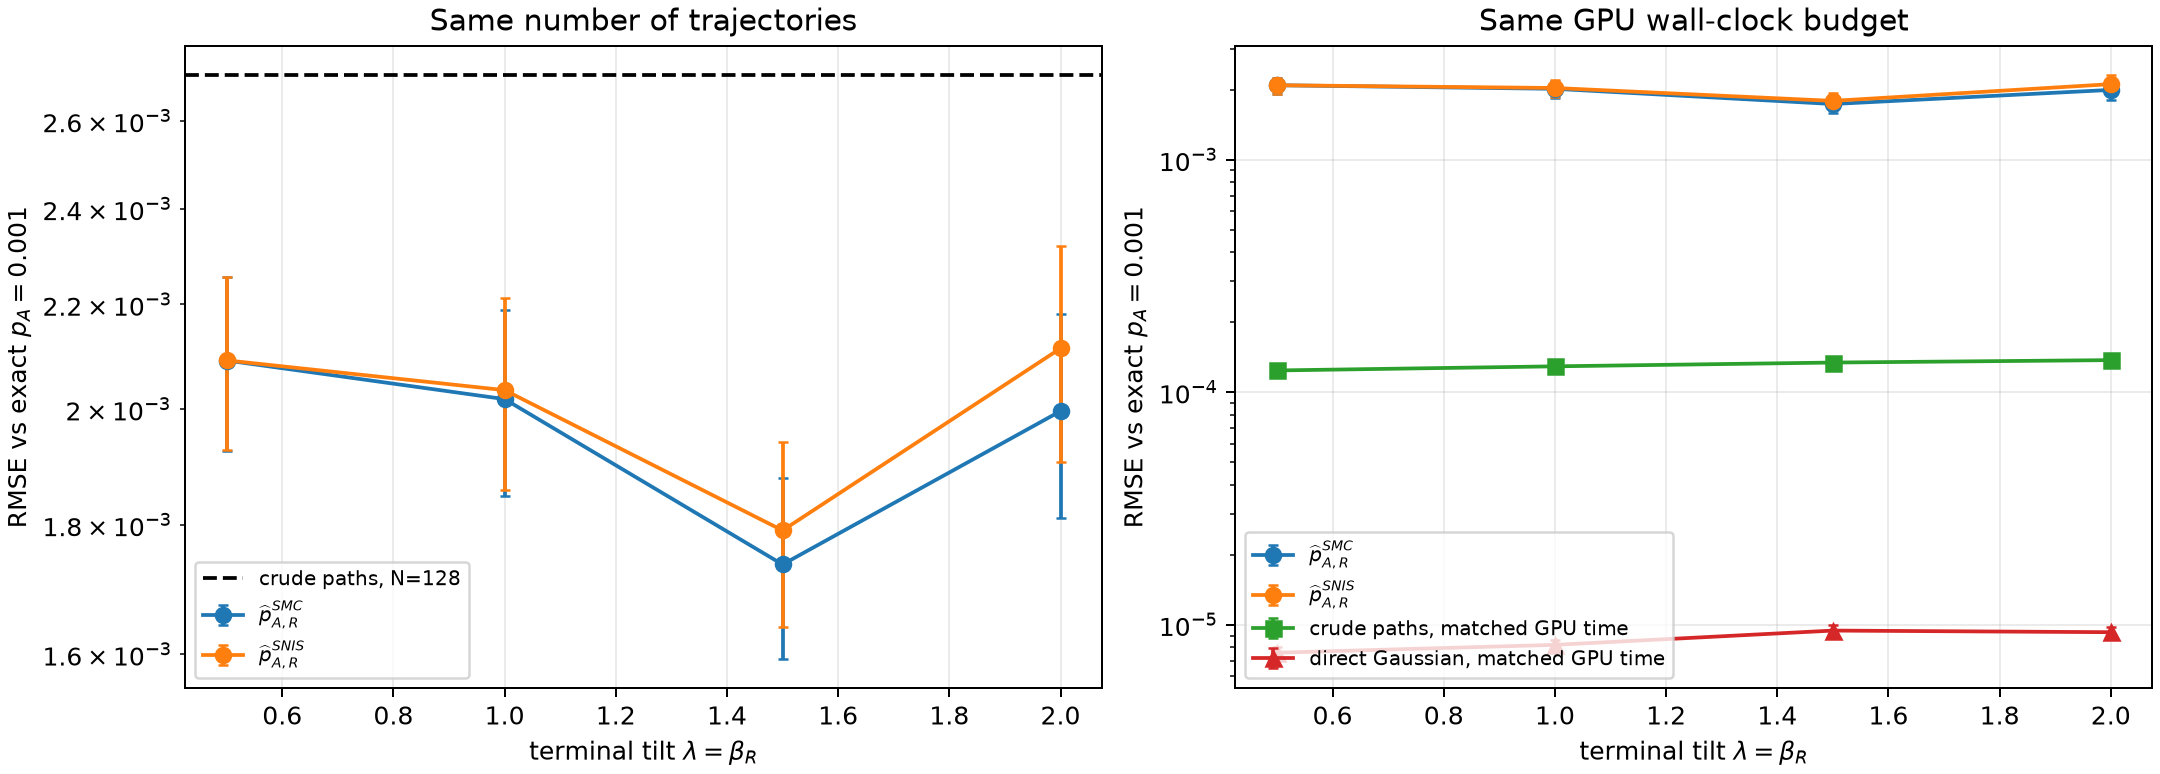

In [5]:
from IPython.display import display, Image
print('Parameters and effective execution:')
print((OUT / 'parameters.json').read_text())
print('N=64 pilot:')
display(pd.read_csv(OUT / 'pilot_summary_N64.csv'))
print('N=128 main experiment and matched GPU time:')
display(summary[['method','lambda','n','reps','bias','bias_se','variance','rmse','rmse_se','zero_fraction','median_ms','median_transitions','median_gaussian_draws','resampling_run_fraction']])
comparison = pd.read_csv(OUT / 'comparison.csv')
display(comparison)
display(Image(filename=str(OUT / 'rmse_comparison.png')))

Diagnostic distributions: min, 5%, 25%, median, 75%, 95%, max by tilt and level:


,lambda,stage,metric,n,mean,sd,minimum,p05,p25,median,p75,p95,maximum
0,0.5,before_resampling_k1,pre_ess_fraction,1200,0.984579,0.001916,0.977345,0.981329,0.983360,0.984587,0.985882,0.987646,0.990303
1,0.5,before_resampling_k1,pre_max_weight,1200,0.010732,0.000550,0.009564,0.009954,0.010363,0.010659,0.011031,0.011728,0.013447
2,0.5,before_resampling_k1,resampled,1200,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.5,before_resampling_k2,pre_ess_fraction,1200,0.953525,0.006581,0.925023,0.942058,0.949613,0.953793,0.957880,0.963952,0.969635
4,0.5,before_resampling_k2,pre_max_weight,1200,0.013756,0.001410,0.011096,0.011899,0.012814,0.013537,0.014448,0.016387,0.021462
...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,2.0,genealogy,distinct_root_fraction,1200,0.611354,0.049754,0.296875,0.523438,0.570312,0.617188,0.648438,0.679688,0.734375
64,2.0,reverse,reverse_ess_fraction,1200,0.233104,0.099554,0.021172,0.071065,0.162249,0.229857,0.302849,0.402304,0.552158
65,2.0,reverse,reverse_max_weight,1200,0.133655,0.078961,0.036394,0.056592,0.080947,0.110708,0.160854,0.297914,0.598973
66,2.0,terminal,terminal_ess_fraction,1200,0.616041,0.190473,0.208417,0.348764,0.472402,0.556665,0.846715,0.888761,0.911853


Conditional bias, RMSE, and zero estimates by diagnostic quantile (descriptive):


,lambda,diagnostic,bin,method,runs,diagnostic_min,diagnostic_median,diagnostic_max,bias,rmse,zero_fraction
0,0.5,terminal_ess_fraction,0,smc,300,0.681477,0.831663,0.844659,0.000787,0.003076,0.666667
1,0.5,terminal_ess_fraction,0,snis,300,0.681477,0.831663,0.844659,0.000781,0.003067,0.666667
2,0.5,terminal_ess_fraction,1,smc,300,0.844671,0.853396,0.861776,0.000018,0.001974,0.740000
3,0.5,terminal_ess_fraction,1,snis,300,0.844671,0.853396,0.861776,0.000019,0.001973,0.740000
4,0.5,terminal_ess_fraction,2,smc,300,0.861929,0.868012,0.875022,-0.000249,0.001525,0.766667
...,...,...,...,...,...,...,...,...,...,...,...
79,2.0,distinct_root_fraction,1,snis,294,0.578125,0.601562,0.617188,0.000877,0.003162,0.282313
80,2.0,distinct_root_fraction,2,smc,325,0.625000,0.640625,0.648438,0.000056,0.001627,0.298462
81,2.0,distinct_root_fraction,2,snis,325,0.625000,0.640625,0.648438,0.000087,0.001675,0.298462
82,2.0,distinct_root_fraction,3,smc,272,0.656250,0.671875,0.734375,-0.000247,0.001270,0.330882


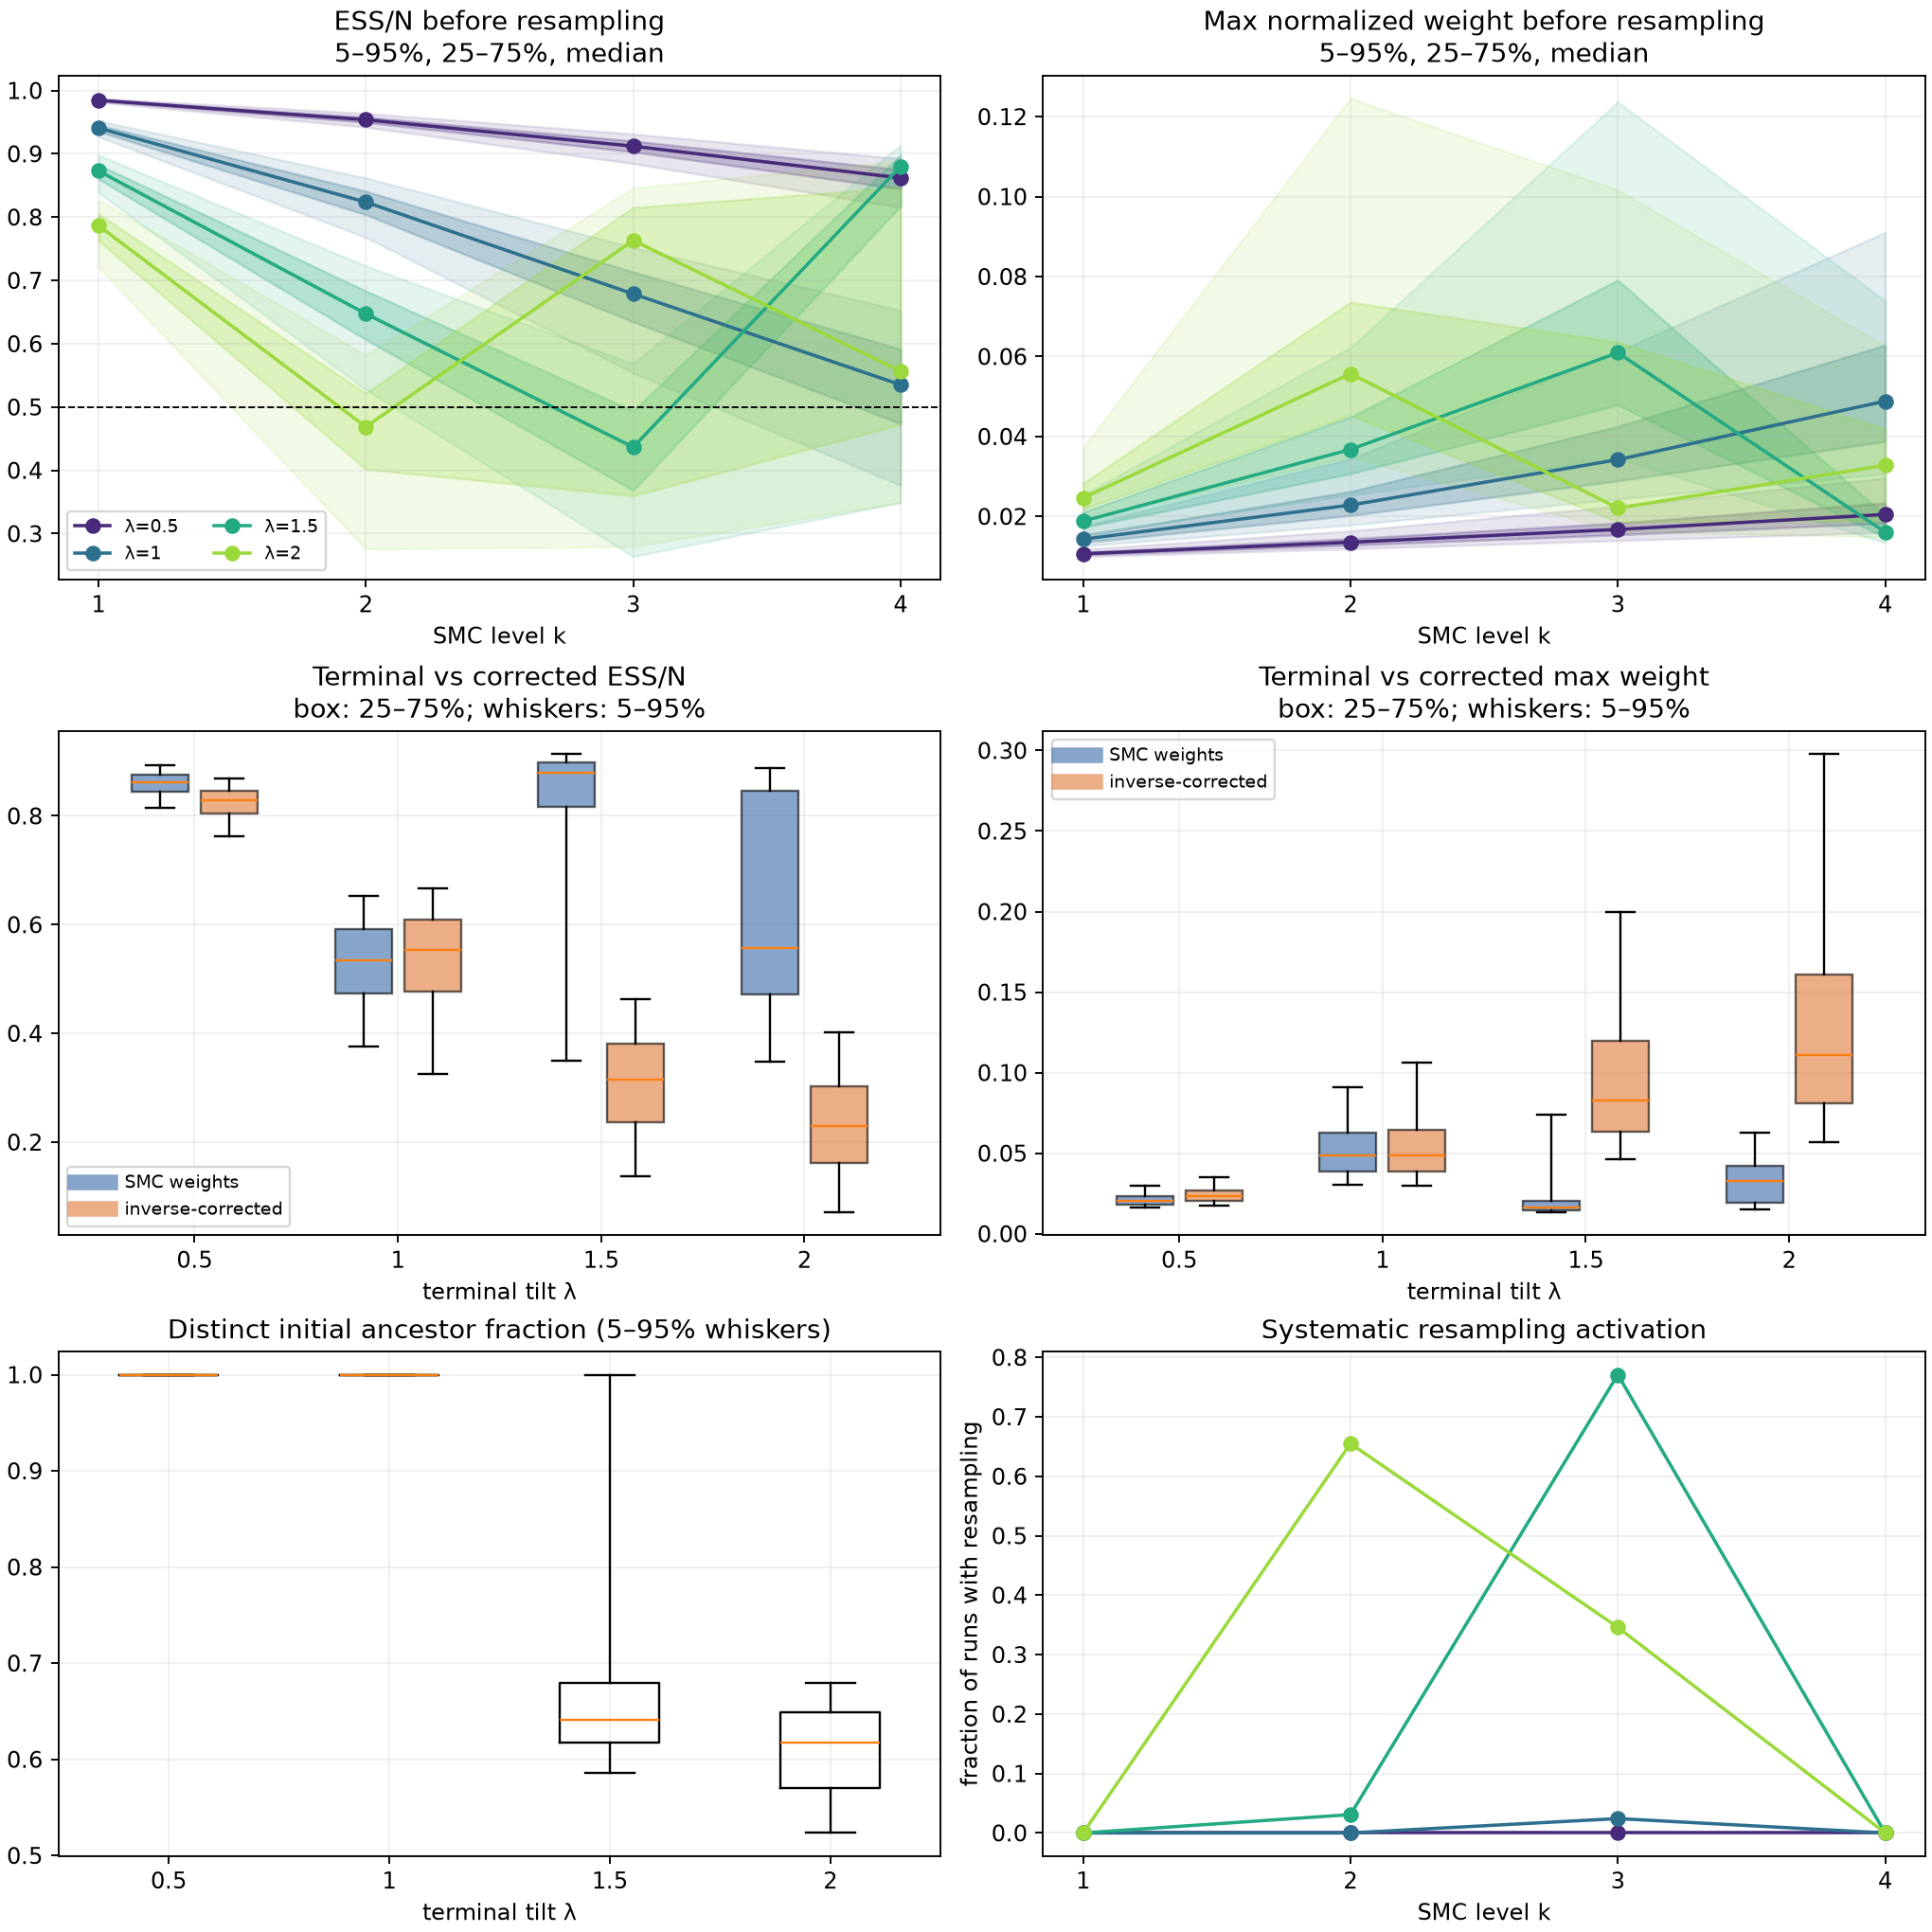

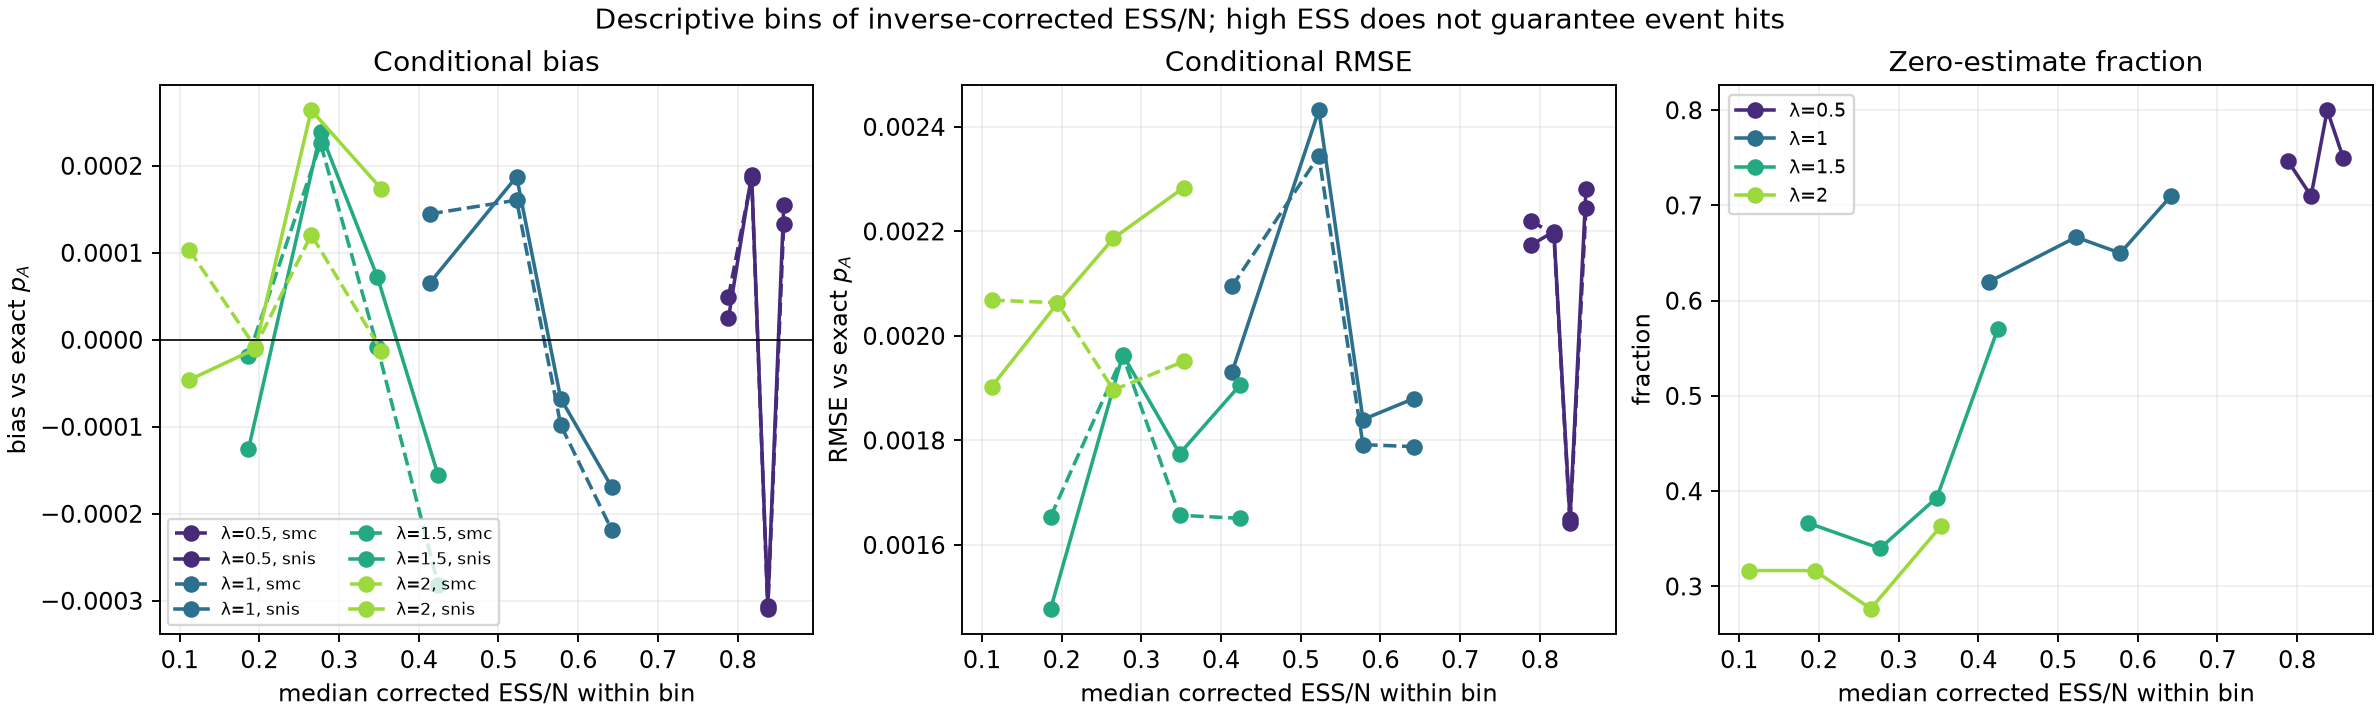

In [6]:
diagnostics = pd.read_csv(OUT / 'diagnostic_quantiles.csv')
association = pd.read_csv(OUT / 'diagnostic_error_association.csv')
print('Diagnostic distributions: min, 5%, 25%, median, 75%, 95%, max by tilt and level:')
display(diagnostics)
print('Conditional bias, RMSE, and zero estimates by diagnostic quantile (descriptive):')
display(association)
display(Image(filename=str(OUT / 'weight_degeneracy.png')))
display(Image(filename=str(OUT / 'degeneracy_error_association.png')))

In [7]:
best = comparison.loc[comparison.snis_rmse.idxmin()]
print(f"A N=128, miglior reverse-SNIS nella griglia: lambda={best['lambda']:.2f}, RMSE={best.snis_rmse:.6f}, contro crude MC N=128: {best.crude_N128_rmse:.6f}.")
print(f"A pari wall clock GPU misurato: reverse-SNIS {best.snis_rmse:.6f} in {best.smc_median_ms:.3f} ms; crude MC da traiettorie complete {best.crude_matched_rmse:.6f} con {int(best.crude_matched_n)} traiettorie in {best.crude_matched_median_ms:.3f} ms.")
print(f"Errore standard Monte Carlo della differenza di RMSE: {best.snis_minus_crude_matched_RMSE_se:.6f}; rapporto dei tempi crude/SMC: {best.time_ratio_crude_over_smc:.3f}.")
print(f"Rapporti dei tempi su tutta la griglia: [{comparison.time_ratio_crude_over_smc.min():.3f}, {comparison.time_ratio_crude_over_smc.max():.3f}].")
print('I due stimatori SMC condividono la popolazione e il costo. Un ESS alto da solo non garantisce una stima accurata di un evento raro.')

A N=128, miglior reverse-SNIS nella griglia: lambda=1.50, RMSE=0.001791, contro crude MC N=128: 0.002712.
A pari wall clock GPU misurato: reverse-SNIS 0.001791 in 5.833 ms; crude MC da traiettorie complete 0.000134 con 55552 traiettorie in 5.980 ms.
Errore standard Monte Carlo della differenza di RMSE: 0.000077; rapporto dei tempi crude/SMC: 1.025.
Rapporti dei tempi su tutta la griglia: [0.987, 1.025].
I due stimatori SMC condividono la popolazione e il costo. Un ESS alto da solo non garantisce una stima accurata di un evento raro.


## Interpretazione

Il grafico di sinistra confronta **N=128** traiettorie per metodo; quello di destra confronta il costo misurato di una run SMC con il numero di traiettorie crude che la GPU genera in un tempo simile. Lo stesso tempo SMC vale per $\widehat p_{A,R}^{SMC}$ e $\widehat p_{A,R}^{SNIS}$ perché provengono dalla medesima popolazione. `summary.csv` riporta bias, varianza empirica, RMSE, errore standard Monte Carlo dell'RMSE, stime nulle, tempi e transizioni. `runs.csv` contiene ogni replica e seed. Il grafico include intervalli approssimati al 95% di sola incertezza Monte Carlo dell'RMSE. `level_diagnostics.csv` e `diagnostic_quantiles.csv` rendono visibili i livelli e le distribuzioni; `diagnostic_error_association.csv` confronta la degenerazione con errori e stime nulle.

La stima $\widehat Z_R$ e il denominatore SNIS sono casuali; nel caso con resampling le storie delle particelle sono dipendenti. Non attribuiamo loro la varianza derivata per storie indipendenti senza resampling. La concentrazione genealogica può persistere anche quando il resampling reimposta i pesi a $1/N$; viceversa un ESS alto non assicura che l'evento raro sia stato osservato. Le associazioni condizionali sono descrittive, non causali. I risultati a particelle uguali e a tempo uguale rispondono a domande distinte.